In [1]:
import numpy as np
import gymnasium as gym
import torch
# python -m ipykernel install --user --name=Gym-RL --display-name "Python (Gym-RL)"
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
import matplotlib.pyplot as plt
# The "ipympl" backend is better, as it allows for interactiveness, but on some installations it does not work, then use "inline"
%matplotlib ipympl
# %matplotlib inline  

# this way of importing allow to reload/refresh the module later with importlib.reload(policy)
import policy as policy 
import memory as mem
from feedforward import Feedforward

Load environment, policy and memory.

In [2]:
env = gym.make('Pendulum-v1', g=9.81, render_mode="human")
pi = policy.PDPolicy(env)
buffer = mem.Memory()

## Inspect the environment 

In [3]:
s , _ = env.reset()
for t in range(100):
    a = pi.get_action(s) 
    s_new, rew, term, trunc, _ = env.step(a)
    buffer.add_transition([s,a,rew,s_new, term, trunc])
    s = s_new

In [4]:
transitions = buffer.get_all_transitions()
states = np.vstack(transitions[:,0])
actions = transitions[:,1]
rewards = transitions[:,2]

Plot the trajectory: (state, action, reward)
 
 The state is [position-x, position-y, angular velocity] 
 
 **changes are needed**

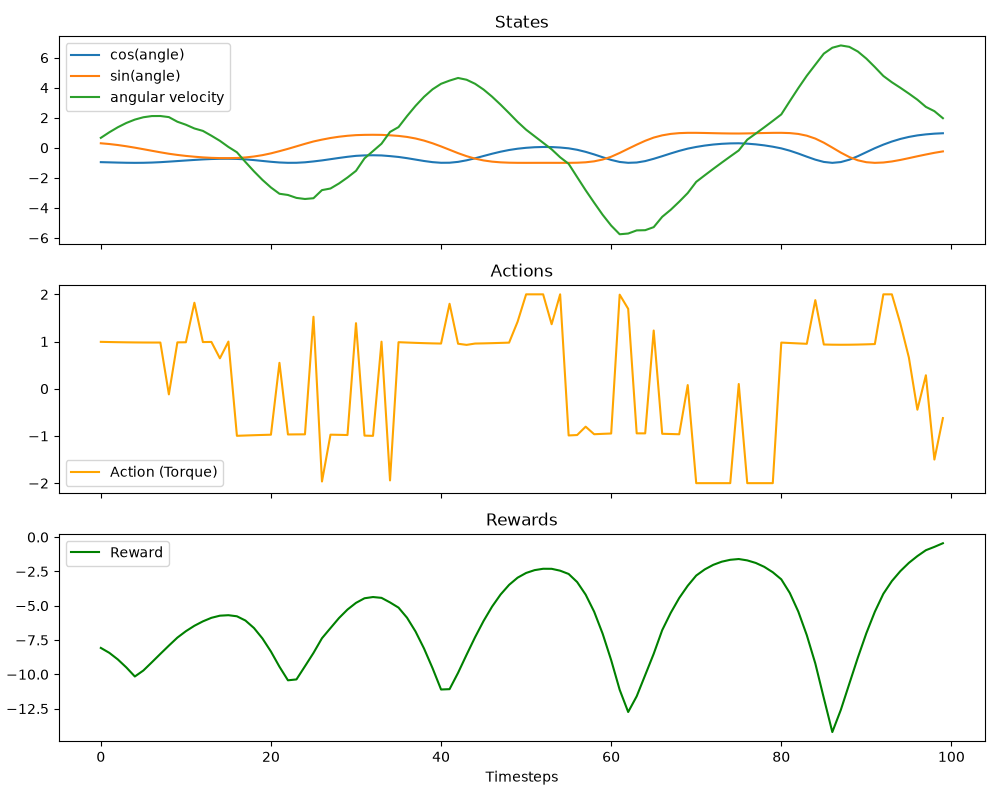

In [5]:
transitions = buffer.get_all_transitions()
states = np.vstack(transitions[:100, 0])
actions = np.vstack(transitions[:100, 1]).ravel()
rewards = np.vstack(transitions[:100, 2]).ravel()

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].plot(states[:, 0], label="cos(angle)")
axes[0].plot(states[:, 1], label="sin(angle)")
axes[0].plot(states[:, 2], label="angular velocity")
axes[0].legend()
axes[0].set_title("States")

axes[1].plot(actions, color="orange", label="Action (Torque)")
axes[1].legend()
axes[1].set_title("Actions")

axes[2].plot(rewards, color="green", label="Reward")
axes[2].legend()
axes[2].set_title("Rewards")
axes[2].set_xlabel("Timesteps")

plt.tight_layout()

# Collect data

We do 500 rollouts a 100 timesteps with the black box policy. Nothing needs to be changed here.

In [6]:
env = gym.make('Pendulum-v1', g=9.81, render_mode=None) # switch off rendering
for ep in range(500):
    # start a larger range initial conditions to see enough of the statespace
    s, _ = env.reset(options={"y_init": 4.0})
    for t in range(100):
        a = pi.get_action(s) 
        s_new, rew, term, trunc, _ = env.step(a)
        buffer.add_transition([s,a,rew,s_new, term, trunc])
        s = s_new

In [7]:
buffer.size

50100

# Fit value function

The value function fitting class. Here, you need to fill in the blank parts

In [8]:
class ValueFunction(Feedforward):
    def __init__(self, observation_dim, hidden_sizes=[100,100]):
        super().__init__(input_size=observation_dim, hidden_sizes=hidden_sizes, output_size=1)
        
        # so this class is already a neural network, see feedforward.py        
        # add and optimizer here (e.g. Adam with lr = 0.0002, eps=0.000001)
        self.optimizer = torch.optim.Adam(self.parameters(), lr=0.0002, eps=0.000001)
        
        # add a loss function here
        self.loss = torch.nn.MSELoss()
    
    def fit(self, observations, targets):
        # Add one training step here. 
        # The states are called here observations        
        self.optimizer.zero_grad()
        
        # Hints:         
        # convert the inputs into torch tensors with torch.from_numpy
        obs_tensor = torch.from_numpy(observations).float()
        target_tensor = torch.from_numpy(targets).float().float().reshape(-1, 1)
        # use self.forward(input) to make a prediction to be used in the loss
        predictions = self.forward(obs_tensor)
        loss = self.loss(predictions, target_tensor)

        loss.backward()
        self.optimizer.step()
        # return the current loss
        return loss.item()

Fitting routine of the value function. Fill in the blank parts.

In [9]:
def plot_value_function(value_function):
    plt.rcParams.update({'font.size': 12})
    xxs =np.linspace(-np.pi/2,np.pi/2)
    yys =np.linspace(-3,3)
    XX,YY=np.meshgrid(xxs,yys)
    dots=np.asarray([np.cos(XX.ravel()),np.sin(XX.ravel()),YY.ravel()]).T
    print(dots.shape)
    # values = np.asarray(test_func(dots)).reshape(XX.shape)
    values =value_function.predict(dots).reshape(XX.shape)

    fig = plt.figure(figsize=[10,8])
    ax = fig.add_subplot(projection='3d')
    surf = ax.plot_surface(XX, YY, values, cmap=cm.coolwarm,
                           linewidth=0, antialiased=False)
    ax.view_init(elev=30, azim=45, roll=0)
    ax.set_xlabel('angle')
    ax.set_ylabel('angle velocity')
    ax.set_zlabel('value')
    # plt.colorbar(cmap=cm.coolwarm)
    return fig

(2500, 3)


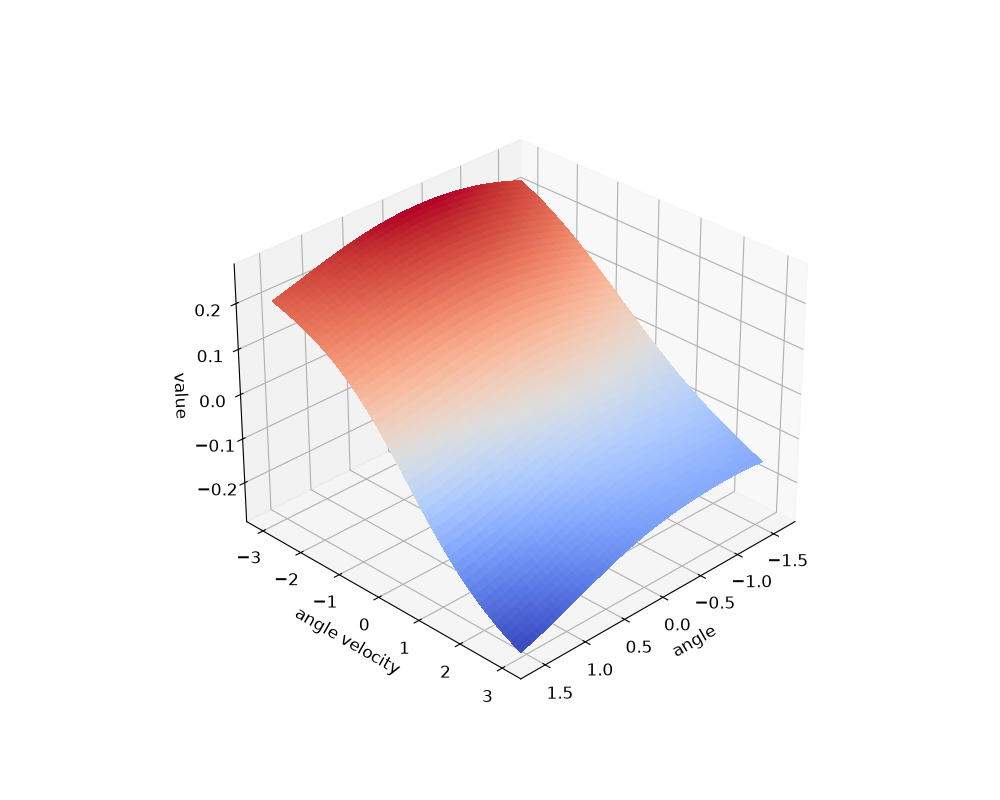

In [10]:
valuefunc = ValueFunction(observation_dim=env.observation_space.shape[0])
fig_before = plot_value_function(valuefunc)
fig_before.savefig("value_approx_before.pdf", bbox_inches="tight")

In [11]:
plt_fit = []

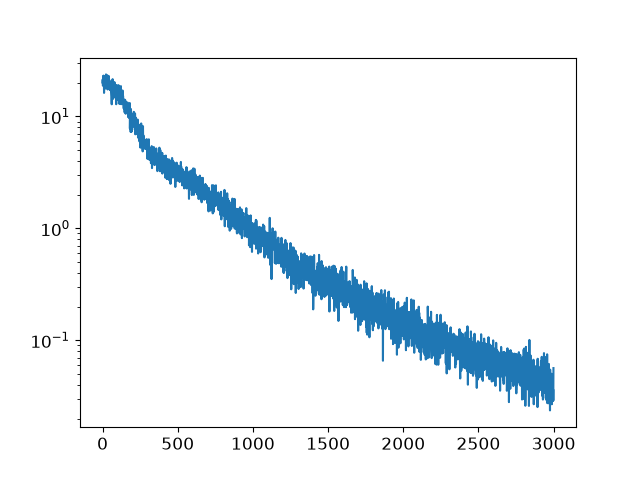

In [12]:
iter_fit = 3000# do at least 2000
gamma=0.5
for i in range(iter_fit):

    # sample from the replay buffer
    data=buffer.sample(batch=512)
    # each entry in data is (state,action,reward,next_state, term, trunc)    
    
    # Hints:
    #  use can use np.stack to convert the array or arrays into one array
    #  it is really important that you check the shapes of your arrays.
    #  It should be (512,3) for the state and (512,1) for reward and values
    
    state = np.vstack(data[:,0])
    next_state = np.vstack(data[:, 3])
    reward = np.vstack(data[:,2])
    term = np.vstack(data[:, 4])
    trunc = np.vstack(data[:,5])

    with torch.no_grad():
        next_values = valuefunc.predict(next_state)
        done = np.logical_or(term, trunc)
        td_target = reward + gamma * next_values * (~done) 
    
    # optimize the least squared objective
    fit_loss = valuefunc.fit(state, td_target)
    
    plt_fit.append(fit_loss)
    
# plot the loss
plt.figure()
plt.yscale("log")
plt.plot(range(len(plt_fit)),plt_fit)

(2500, 3)


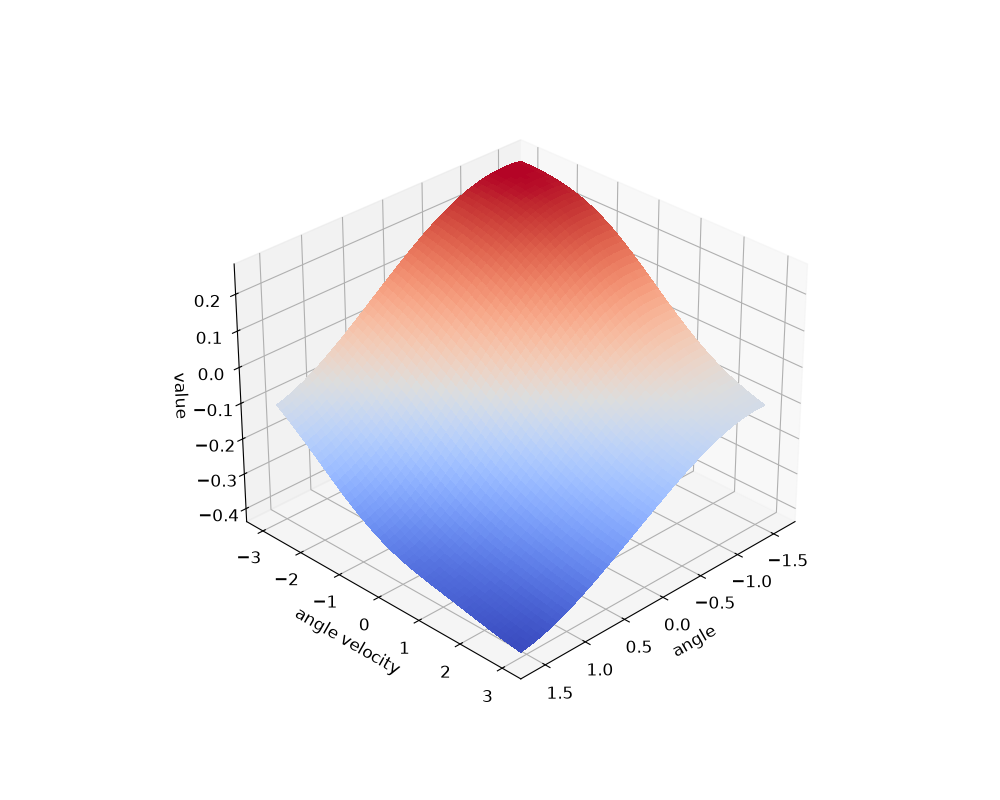

In [13]:
valuefunc = ValueFunction(observation_dim=env.observation_space.shape[0])
fig_after = plot_value_function(valuefunc)
fig_after.savefig("value_approx.pdf", bbox_inches="tight")

# Visualize

Visualization of the value function. Nothing needs to be changed here.

In [14]:
fig.savefig("value_approx.pdf", bbox_inches="tight")
fig.savefig("value_approx.pdf", bbox_inches="tight")